In [ ]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import geopandas as gpd

In [ ]:
df_2025 = pd.read_csv('2025.csv', sep=';', encoding='latin1', low_memory=False)

# Filtro de voos com passageiros ou decolagens
df_voos = df_2025[df_2025['DECOLAGENS'] > 0].copy()

# Digrafo dirigido
G = nx.DiGraph()

# Agrupar por Origem e Destino para somar passageiros e decolagens no ano
df_rotas = df_voos.groupby([
    'AEROPORTO DE ORIGEM (SIGLA)', 'AEROPORTO DE ORIGEM (NOME)', 'AEROPORTO DE ORIGEM (UF)', 'AEROPORTO DE ORIGEM (REGIÃO)',
    'AEROPORTO DE DESTINO (SIGLA)', 'AEROPORTO DE DESTINO (NOME)', 'AEROPORTO DE DESTINO (UF)', 'AEROPORTO DE DESTINO (REGIÃO)'
]).agg({
    'PASSAGEIROS PAGOS': 'sum',
    'DECOLAGENS': 'sum'
}).reset_index()

# Adicionar nós e arestas com atributos ricos
for _, row in df_rotas.iterrows():
    u = row['AEROPORTO DE ORIGEM (SIGLA)']
    v = row['AEROPORTO DE DESTINO (SIGLA)']

    # Atributos dos Nós
    if u not in G:
        G.add_node(u, nome=row['AEROPORTO DE ORIGEM (NOME)'], uf=row['AEROPORTO DE ORIGEM (UF)'], regiao=row['AEROPORTO DE ORIGEM (REGIÃO)'])
    if v not in G:
        G.add_node(v, nome=row['AEROPORTO DE DESTINO (NOME)'], uf=row['AEROPORTO DE DESTINO (UF)'], regiao=row['AEROPORTO DE DESTINO (REGIÃO)'])

    # Aresta com múltiplos pesos
    G.add_edge(u, v, weight=row['DECOLAGENS'], passageiros=row['PASSAGEIROS PAGOS'])

print("Nós (Aeródromos):", G.number_of_nodes())
print("Arestas (Rotas):", G.number_of_edges())

Nós (Aeródromos): 177
Arestas (Rotas): 1718


=== MÉTRICAS DA REDE ===
Número de Nós (Aeródromos): 177
Número de Arestas (Rotas Direcionadas): 1718
Densidade do Grafo: 0.0551


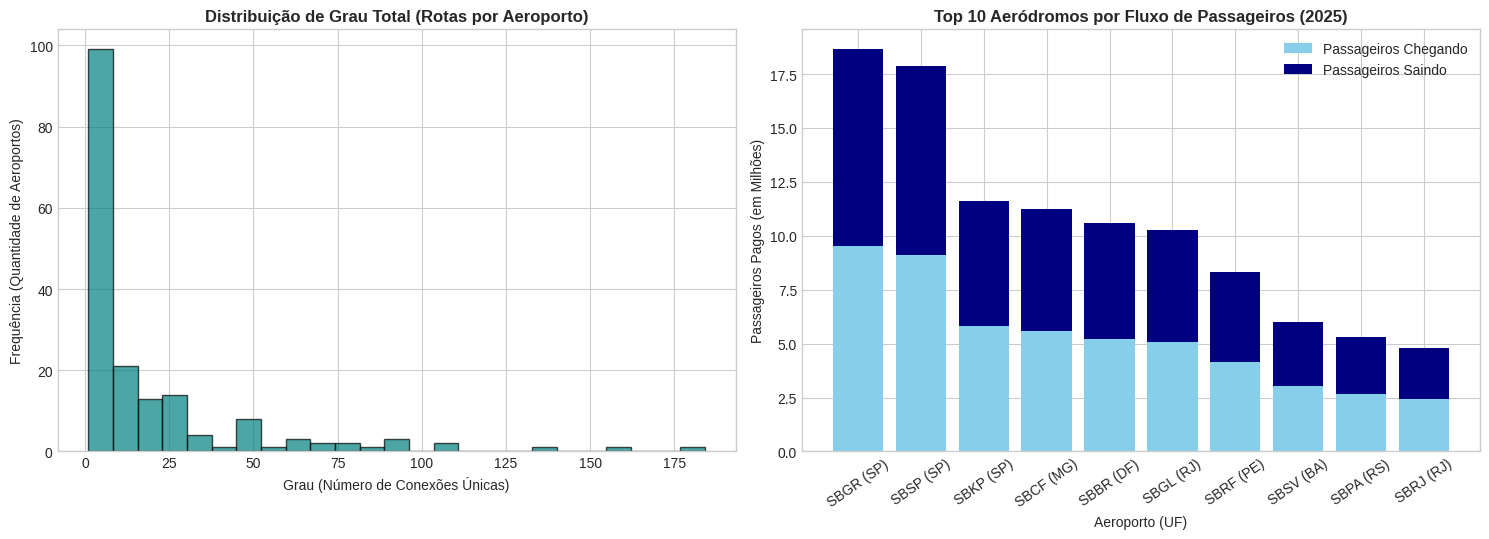

In [ ]:
# MÉTRICAS TOPOLÓGICAS BÁSICAS
print("=== MÉTRICAS DA REDE ===")
print(f"Número de Nós (Aeródromos): {G.number_of_nodes()}")
print(f"Número de Arestas (Rotas Direcionadas): {G.number_of_edges()}")
print(f"Densidade do Grafo: {nx.density(G):.4f}")

# CÁLCULO DOS GRAUS NÃO PONDERADOS E PONDERADOS
in_simple = dict(G.in_degree())
out_simple = dict(G.out_degree())
in_decolagens = dict(G.in_degree(weight='weight'))
out_decolagens = dict(G.out_degree(weight='weight'))
in_pax = dict(G.in_degree(weight='passageiros'))
out_pax = dict(G.out_degree(weight='passageiros'))

nodes_list = list(G.nodes())
df_nodes = pd.DataFrame(index=nodes_list)
df_nodes['Nome'] = [G.nodes[n].get('nome', '') for n in nodes_list]
df_nodes['UF'] = [G.nodes[n].get('uf', '') for n in nodes_list]
df_nodes['Regiao'] = [G.nodes[n].get('regiao', '') for n in nodes_list]

df_nodes['Rotas_In'] = [in_simple[n] for n in nodes_list]
df_nodes['Rotas_Out'] = [out_simple[n] for n in nodes_list]
df_nodes['Decolagens_In'] = [in_decolagens[n] for n in nodes_list]
df_nodes['Decolagens_Out'] = [out_decolagens[n] for n in nodes_list]
df_nodes['Pax_In'] = [in_pax[n] for n in nodes_list]
df_nodes['Pax_Out'] = [out_pax[n] for n in nodes_list]

df_nodes['Rotas_Total'] = df_nodes['Rotas_In'] + df_nodes['Rotas_Out']
df_nodes['Pax_Total'] = df_nodes['Pax_In'] + df_nodes['Pax_Out']
df_nodes['Rotulo'] = df_nodes.index + " (" + df_nodes['UF'] + ")"

df_nodes = df_nodes.sort_values(by='Pax_Total', ascending=False)

# GRÁFICOS DO BLOCO 1
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Visualização 1: Distribuição de Grau
degrees = [d for n, d in G.degree()]
axes[0].hist(degrees, bins=25, color='teal', edgecolor='black', alpha=0.7)
axes[0].set_title('Distribuição de Grau Total (Rotas por Aeroporto)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Grau (Número de Conexões Únicas)')
axes[0].set_ylabel('Frequência (Quantidade de Aeroportos)')

# Visualização 2: Top 10 Aeroportos por Passageiros Pagos
top10 = df_nodes.head(10)
axes[1].bar(top10['Rotulo'], top10['Pax_In'] / 1e6, label='Passageiros Chegando', color='skyblue')
axes[1].bar(top10['Rotulo'], top10['Pax_Out'] / 1e6, bottom=top10['Pax_In'] / 1e6, label='Passageiros Saindo', color='navy')
axes[1].set_title('Top 10 Aeródromos por Fluxo de Passageiros (2025)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Aeroporto (UF)')
axes[1].set_ylabel('Passageiros Pagos (em Milhões)')
axes[1].tick_params(axis='x', rotation=35)
axes[1].legend()

plt.tight_layout()
plt.savefig('bloco1_topologia_geral.png', dpi=300)
plt.show()

In [ ]:
pip install geopandas

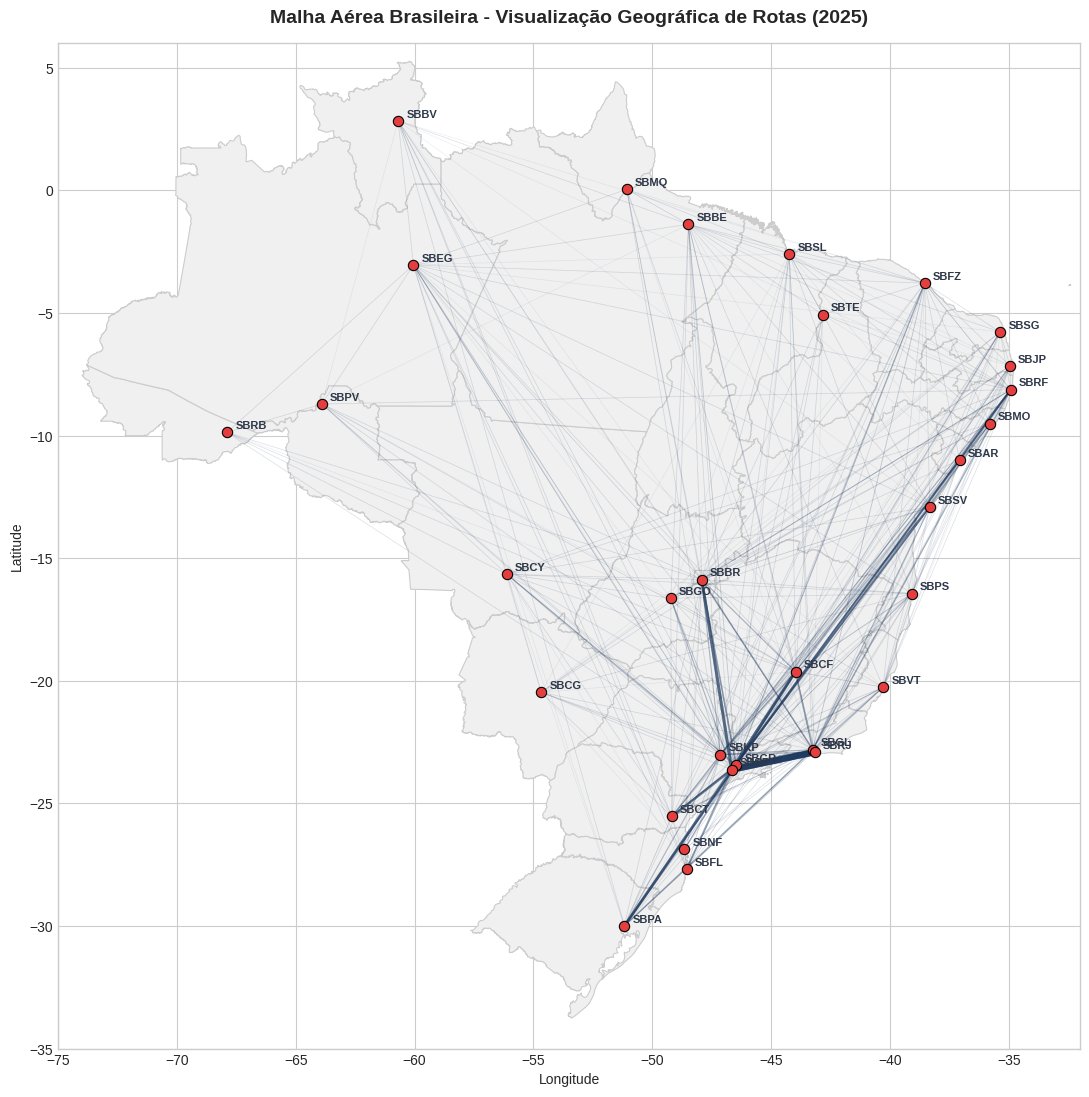

In [ ]:
# Dicionário de Coordenadas dos Aeroportos (Latitude, Longitude)
coords = {
    'SBGR': (-23.4356, -46.4731), 'SBSP': (-23.6261, -46.6564), 'SBBR': (-15.8697, -47.9172),
    'SBCF': (-19.6244, -43.9719), 'SBGL': (-22.8089, -43.2436), 'SBRJ': (-22.9100, -43.1625),
    'SBKP': (-23.0074, -47.1345), 'SBRF': (-8.1264, -34.9228),  'SBSV': (-12.9086, -38.3225),
    'SBPA': (-29.9939, -51.1711), 'SBCT': (-25.5317, -49.1761), 'SBFZ': (-3.7763, -38.5326),
    'SBFL': (-27.6703, -48.5525), 'SBBE': (-1.3792, -48.4763),  'SBEG': (-3.0386, -60.0497),
    'SBVT': (-20.2581, -40.2864), 'SBGO': (-16.6325, -49.2211), 'SBCY': (-15.6528, -56.1167),
    'SBSG': (-5.7689, -35.3663),  'SBJP': (-7.1481, -34.9503),  'SBSL': (-2.5867, -44.2361),
    'SBMO': (-9.5108, -35.7917),  'SBAR': (-10.9840, -37.0703), 'SBTE': (-5.0594, -42.8236),
    'SBPV': (-8.7094, -63.9022),  'SBRB': (-9.8683, -67.8983),  'SBMQ': (0.0506, -51.0722),
    'SBBV': (2.8414, -60.6922),   'SBCG': (-20.4686, -54.6725), 'SBPS': (-16.4386, -39.0778),
    'SBNF': (-26.8786, -48.6514)
}

# Filtragem rotas com coordenadas conhecidas
df_br = df_voos[
    df_voos['AEROPORTO DE ORIGEM (SIGLA)'].isin(coords.keys()) &
    df_voos['AEROPORTO DE DESTINO (SIGLA)'].isin(coords.keys())
].groupby(['AEROPORTO DE ORIGEM (SIGLA)', 'AEROPORTO DE DESTINO (SIGLA)'])['DECOLAGENS'].sum().reset_index()

# Criação da Figura e Carregar o Mapa de Fundo do Brasil
fig, ax = plt.subplots(figsize=(11, 11))

try:
    url_geojson = 'https://raw.githubusercontent.com/codeforamerica/click_that_hood/master/public/data/brazil-states.geojson'
    brasil = gpd.read_file(url_geojson)
    brasil.plot(ax=ax, color='#f0f0f0', edgecolor='#cccccc', linewidth=0.8, zorder=1)
except Exception as e:
    print("Aviso: Não foi possível carregar o mapa via URL. Exibindo com grade de coordenadas.")
    ax.grid(True, linestyle='--', alpha=0.5)

# Desenho das Arestas (Rotas com opacidade e espessura proporcionais ao volume de voos)
max_dec = df_br['DECOLAGENS'].max()
for _, row in df_br.iterrows():
    u, v = row['AEROPORTO DE ORIGEM (SIGLA)'], row['AEROPORTO DE DESTINO (SIGLA)']
    weight = row['DECOLAGENS']
    lat1, lon1 = coords[u]
    lat2, lon2 = coords[v]

    alpha = min(0.8, max(0.08, weight / max_dec))
    linewidth = max(0.5, (weight / max_dec) * 4.5)  # Corrigido a multiplicação
    ax.plot([lon1, lon2], [lat1, lat2], color='#1a365d', alpha=alpha, linewidth=linewidth, zorder=2)

# Desenho dos Nós (Aeroportos)
lons = [coords[k][1] for k in coords.keys()]
lats = [coords[k][0] for k in coords.keys()]
ax.scatter(lons, lats, color='#e53e3e', s=55, zorder=3, edgecolor='black', linewidth=0.8)

# Rótulos dos Aeroportos
for k, (lat, lon) in coords.items():
    ax.text(lon + 0.35, lat + 0.15, k, fontsize=8, fontweight='bold', color='#2d3748', zorder=4)

ax.set_title('Malha Aérea Brasileira - Visualização Geográfica de Rotas (2025)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Longitude', fontsize=10)
ax.set_ylabel('Latitude', fontsize=10)
ax.set_xlim(-75, -32)
ax.set_ylim(-35, 6)

plt.tight_layout()
plt.savefig('mapa_malha_aerea_brasil_geopandas.png', dpi=300)
plt.show()

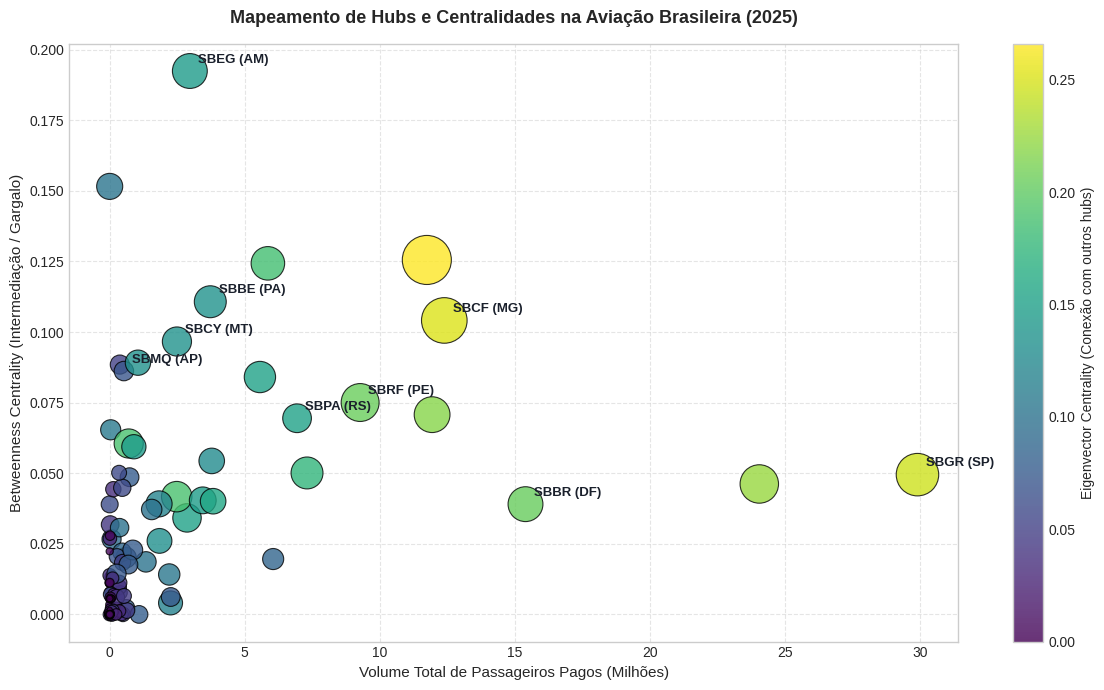

In [ ]:
# Consolidação de rotas por volume de decolagens e passageiros
df_rotas = df_voos.groupby([
    'AEROPORTO DE ORIGEM (SIGLA)', 'AEROPORTO DE ORIGEM (NOME)', 'AEROPORTO DE ORIGEM (UF)', 'AEROPORTO DE ORIGEM (REGIÃO)',
    'AEROPORTO DE DESTINO (SIGLA)', 'AEROPORTO DE DESTINO (NOME)', 'AEROPORTO DE DESTINO (UF)', 'AEROPORTO DE DESTINO (REGIÃO)'
]).agg({
    'DECOLAGENS': 'sum',
    'PASSAGEIROS PAGOS': 'sum'
}).reset_index()

# Grafo Dirigido
G = nx.DiGraph()

for _, row in df_rotas.iterrows():
    u = row['AEROPORTO DE ORIGEM (SIGLA)']
    v = row['AEROPORTO DE DESTINO (SIGLA)']

    if u not in G:
        G.add_node(u, nome=row['AEROPORTO DE ORIGEM (NOME)'], uf=row['AEROPORTO DE ORIGEM (UF)'], regiao=row['AEROPORTO DE ORIGEM (REGIÃO)'])
    if v not in G:
        G.add_node(v, nome=row['AEROPORTO DE DESTINO (NOME)'], uf=row['AEROPORTO DE DESTINO (UF)'], regiao=row['AEROPORTO DE DESTINO (REGIÃO)'])

    G.add_edge(u, v, weight=row['DECOLAGENS'], passageiros=row['PASSAGEIROS PAGOS'])

# Cálculo das centralidades
degree_cent = nx.degree_centrality(G)
betweenness_cent = nx.betweenness_centrality(G, weight='weight')
closeness_cent = nx.closeness_centrality(G)
eigenvector_cent = nx.eigenvector_centrality(G, max_iter=1000)

nodes_list = list(G.nodes())
df_cent = pd.DataFrame(index=nodes_list)
df_cent['Nome'] = [G.nodes[n].get('nome', '') for n in nodes_list]
df_cent['UF'] = [G.nodes[n].get('uf', '') for n in nodes_list]
df_cent['Regiao'] = [G.nodes[n].get('regiao', '') for n in nodes_list]

df_cent['Degree'] = [degree_cent[n] for n in nodes_list]
df_cent['Betweenness'] = [betweenness_cent[n] for n in nodes_list]
df_cent['Closeness'] = [closeness_cent[n] for n in nodes_list]
df_cent['Eigenvector'] = [eigenvector_cent[n] for n in nodes_list]

# Obtenção do volume total de passageiros por nó
pax_dict = dict(G.degree(weight='passageiros'))
df_cent['Passageiros_Total'] = [pax_dict[n] for n in nodes_list]

# PLOTAGEM DO GRÁFICO DE DISPERSÃO
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, ax = plt.subplots(figsize=(12, 7))

# Scatter plot cruzando Passageiros vs Betweenness Centrality
scatter = ax.scatter(
    df_cent['Passageiros_Total'] / 1e6,
    df_cent['Betweenness'],
    s=df_cent['Degree'] * 1200,      # Tamanho do ponto proporcional ao Grau
    c=df_cent['Eigenvector'],        # Cor proporcional ao Eigenvector
    cmap='viridis',
    alpha=0.8,
    edgecolors='black',
    linewidth=0.8
)

# Barra de Cores para Eigenvector
cbar = fig.colorbar(scatter, ax=ax)
cbar.set_label('Eigenvector Centrality (Conexão com outros hubs)', fontsize=10)

# Destacar aeroportos estrategicamente relevantes no gráfico
hubs_destaque = ['SBGR', 'SBBR', 'SBCF', 'SBEG', 'SBCY', 'SBRF', 'SBPA', 'SBBE', 'SBMQ']
for icao in hubs_destaque:
    if icao in df_cent.index:
        row = df_cent.loc[icao]
        ax.annotate(
            f"{icao} ({row['UF']})",
            (row['Passageiros_Total'] / 1e6, row['Betweenness']),
            xytext=(6, 6),
            textcoords='offset points',
            fontsize=9.5,
            fontweight='bold',
            color='#1a202c'
        )

ax.set_title('Mapeamento de Hubs e Centralidades na Aviação Brasileira (2025)', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Volume Total de Passageiros Pagos (Milhões)', fontsize=11)
ax.set_ylabel('Betweenness Centrality (Intermediação / Gargalo)', fontsize=11)
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('bloco2_centralidades_hubs.png', dpi=300)
plt.show()

df_cent.to_csv('resultados_centralidades_2025.csv')